upsc essay evaluation
                                         start
         |                                 |                              |
cot((clarity of thoughts))              language              depth of analysis kaisa hai 
         |                                 |                              |
          ----------------------------Evaluation---------------------------   
                                           |
                                          end            



In [1]:
import os
from dotenv import load_dotenv
from pydantic import BaseModel, Field
from langchain_huggingface import ChatHuggingFace, HuggingFaceEndpoint

In [2]:
load_dotenv()

HF_TOKEN = os.getenv("HF_TOKEN")
HUGGINGFACE_REPO_ID = "Qwen/Qwen2.5-7B-Instruct"

if not HF_TOKEN:
    raise ValueError("HF_TOKEN is missing. Add it to your .env file or environment variables.")

In [3]:
llm = HuggingFaceEndpoint(
    repo_id=HUGGINGFACE_REPO_ID,
    task="text-generation",
    provider="featherless-ai",
    huggingfacehub_api_token=HF_TOKEN,
    temperature=0.5,
)

model = ChatHuggingFace(llm=llm, verbose=True)

In [4]:
class EvaluationSchema(BaseModel):
    feedback: str = Field(..., description='Detailed feedback for the essay')
    score: int = Field(..., description='Score for the essay')


In [5]:
structured_model = model.with_structured_output(
    EvaluationSchema,
    method="json_schema",
)


In [6]:
essay = """Artificial Intelligence and India's Development
Artificial Intelligence (AI) is becoming an important part of India's economic, social, and technological development. AI refers to the ability of machines and computer systems to perform tasks that normally require human intelligence, such as learning, problem-solving, decision-making, language understanding, and pattern recognition. In recent years, the use of AI has increased rapidly across different sectors in India. Healthcare, education, agriculture, banking, manufacturing, transportation, and information technology are some of the major areas where AI is creating new opportunities. With the growth of digital infrastructure and availability of large amounts of data, India has significant potential to benefit from AI.
One of the most important applications of AI is in the healthcare sector. AI systems can assist doctors and healthcare professionals in detecting diseases, analyzing medical images, studying patient records, and identifying possible health risks. For example, AI-based systems can help analyze X-rays, CT scans, and other medical reports to identify patterns that may require further examination. AI can also support hospitals by helping manage patient information, predict demand for medical resources, and improve operational efficiency. However, AI should support healthcare professionals rather than completely replace human judgment, especially when important medical decisions are involved.
Education is another sector where AI can create significant benefits. AI-powered learning platforms can provide personalized learning experiences based on the needs and performance of individual students. Students can use AI-based tools to understand difficult concepts, practice questions, receive feedback, and improve their learning. Teachers can also use AI to analyze student performance and identify areas where additional support may be required. Generative AI tools can assist students and teachers with research, content creation, and learning materials. At the same time, educational institutions need to ensure that students use these technologies responsibly and continue developing critical thinking and problem-solving skills.
Agriculture is one of the most important sectors of the Indian economy, and AI can help improve agricultural productivity. AI-based systems can analyze weather conditions, soil information, satellite images, and crop data to provide useful insights to farmers. Farmers can use AI for crop monitoring, disease detection, irrigation management, and prediction of agricultural conditions. This can help reduce the unnecessary use of water, fertilizers, and pesticides. AI can also support better supply-chain management by helping predict demand and improve the transportation and storage of agricultural products.
The banking and financial services sector is also using AI for various purposes. Banks can use AI to detect unusual transactions, identify potential fraud, assess risks, and provide personalized services to customers. AI-powered chatbots can answer common customer questions and provide support at any time. In addition, machine learning models can analyze large amounts of financial data and help organizations make faster decisions. However, financial institutions must carefully manage customer data and ensure that AI systems are secure and reliable.
Manufacturing and businesses can also benefit from AI and automation. AI can be used to monitor machines, predict equipment failures, improve production processes, and maintain quality standards. Generative AI is becoming increasingly useful for chatbots, customer support, content creation, software development, documentation, and data analysis. By automating repetitive tasks, organizations can allow employees to focus more on creative, analytical, and strategic activities. This can improve productivity and help businesses become more competitive.
Despite these benefits, the growth of AI also creates several challenges. Data privacy is a major concern because AI systems often require large amounts of information. Organizations must protect personal and sensitive data from unauthorized access. Cybersecurity is another important issue because AI systems can be targeted by attackers or misused for harmful purposes. Job displacement is also a concern, particularly for repetitive tasks that can be automated. Therefore, companies, educational institutions, and governments need to focus on reskilling and upskilling workers so that people can adapt to changing job requirements.
India also needs to focus on responsible and ethical AI development. AI systems should be designed to reduce bias, protect privacy, provide transparency, and maintain accountability. Human oversight is important when AI is used for decisions that can significantly affect people's lives. The government and private organizations should work together to create appropriate policies, encourage innovation, and promote safe AI adoption.
In conclusion, Artificial Intelligence has significant potential to support India's economic and digital growth. It can improve productivity, support better decision-making, enhance public and private services, and create new opportunities across different sectors. At the same time, challenges related to privacy, cybersecurity, employment, ethics, and skills cannot be ignored. India needs to develop AI in a responsible and inclusive manner while ensuring that people have access to the education and skills required for the changing technological environment. If AI is developed and used responsibly, it can become an important tool for India's future development and contribute to a more innovative, productive, and digitally advanced society."""

In [7]:
prompt = f"""Evaluate the following essay and provide detailed feedback and a score out of 10 based on the quality of writing, clarity of ideas, coherence, and overall effectiveness. The essay is as follows:
{essay}"""

result = structured_model.invoke(prompt)
print(result['Feedback'])

HfHubHTTPError: Client error '402 Payment Required' for url 'https://router.huggingface.co/featherless-ai/v1/chat/completions' (Request ID: Root=1-6ae49cce-08cb175c4938b439383a0630;90179083-d88a-4ef4-9956-7bcc4be93ad4)
For more information check: https://developer.mozilla.org/en-US/docs/Web/HTTP/Status/402

You have no remaining credits. Purchase pre-paid credits to continue using Inference Providers. Alternatively, subscribe to PRO to get monthly included credits.

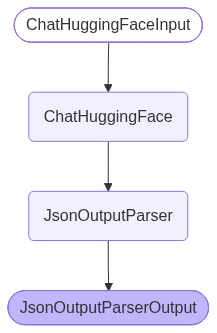

In [19]:
from IPython.display import Image
Image(structured_model.get_graph().draw_mermaid_png())

In [ ]:
# Final evaluation block
# Run this after setting essay variable above.
# prompt = f"""Evaluate the following essay and provide detailed feedback and a score out of 10 based on the quality of writing, clarity of ideas, coherence, and overall effectiveness. The essay is as follows:
# {essay}"""
# result = structured_model.invoke([("user", prompt)])
# print(result.model_dump())


In [ ]:
# if you have a custom essay variable, you can replace it here
# essay = "Your essay text here"
